In [ ]:
!pip install ultralytics opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from google.colab import files

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("VisionPort model loaded successfully!")

VisionPort model loaded successfully!


In [ ]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)

Saving traffic image.webp to traffic image.webp
Image uploaded: traffic image.webp


In [ ]:
# Detect objects in the image
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Object detection completed!")


image 1/1 /content/traffic image.webp: 384x640 11 persons, 15 cars, 2 buss, 1 truck, 257.5ms
Speed: 14.6ms preprocess, 257.5ms inference, 25.9ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
Object detection completed!


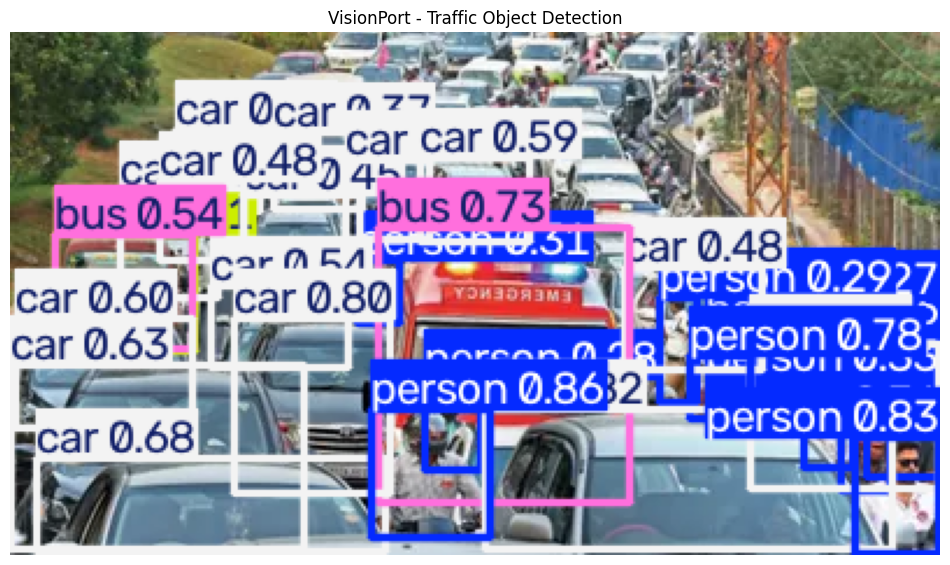

In [ ]:
# Get image with bounding boxes
output_image = results[0].plot()

# Convert BGR to RGB
output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("VisionPort - Traffic Object Detection")
plt.show()

In [ ]:
for box in results[0].boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    confidence = float(box.conf[0])

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

Object: person | Confidence: 85.59 %
Object: person | Confidence: 82.82 %
Object: car | Confidence: 82.25 %
Object: car | Confidence: 79.76 %
Object: person | Confidence: 77.75 %
Object: bus | Confidence: 73.46 %
Object: car | Confidence: 68.02 %
Object: car | Confidence: 65.57 %
Object: car | Confidence: 63.09 %
Object: car | Confidence: 60.47 %
Object: car | Confidence: 58.5 %
Object: car | Confidence: 55.48 %
Object: bus | Confidence: 54.07 %
Object: car | Confidence: 53.99 %
Object: car | Confidence: 47.92 %
Object: car | Confidence: 47.63 %
Object: car | Confidence: 44.87 %
Object: car | Confidence: 37.25 %
Object: car | Confidence: 37.2 %
Object: person | Confidence: 36.28 %
Object: person | Confidence: 33.23 %
Object: person | Confidence: 31.37 %
Object: truck | Confidence: 31.29 %
Object: person | Confidence: 29.05 %
Object: car | Confidence: 28.12 %
Object: person | Confidence: 27.69 %
Object: person | Confidence: 26.83 %
Object: person | Confidence: 25.99 %
Object: person | C